# Final model: PreActResNet + SLA for CIFAR-10 (≤ 5M parameters)

This notebook shows the final model of the project. It does these steps:

1. It counts the trainable parameters with `torchsummary`.
2. It loads the trained weights from `models/`.
3. It calculates the holdout accuracy of the same recipe trained on 45,000 images.
4. It makes the test predictions of the final model and writes `submission.csv`.
5. It plots the training curves and the results of all experiments.

Before you run it, do `python src/prepare_data.py` one time. This makes `data/cifar10_cache.npz` from the Kaggle files.
The full record of all experiments is in `docs/LOGBOOK.md`.

In [1]:
import json, os, sys, glob
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('../src'))
from torchsummary import summary
from models import count_params
from train import load_run, load_data, split, predict, sla_aggregate

ROOT = os.path.abspath('..')
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', device)

device: mps


## 1. Architecture and parameter count

The model is a pre-activation ResNet (He et al., 2016): a 3×3 stem, three stages of 4, 4 and 3 basic blocks
(widths 64, 128, 256), global average pooling and a linear classifier. Each block is
BN → ReLU → conv 3×3 → BN → ReLU → conv 3×3 plus a skip connection (identity or 1×1 conv).
For SLA (Lee et al., 2020), the model also has a 40-way joint head (10 classes × 4 rotations).

In [2]:
def load_model(name):
    cfg = json.load(open(f'{ROOT}/models/{name}.json'))
    from train import build_net
    net = build_net(cfg['arch'], cfg['widths'], cfg['depth'], cfg['ssl'], cfg.get('blur', False))
    net.load_state_dict(torch.load(f'{ROOT}/models/{name}.pt', map_location='cpu'))
    return net.to(device).eval(), cfg

final, final_cfg = load_model('final_preact_sla_50k')
summary(final.cpu(), (3, 32, 32), device='cpu')
final.to(device)
n_all = count_params(final)
print(f'Trainable parameters, all modules (incl. the 40-way SLA head): {n_all:,}')
assert n_all <= 5_000_000

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
            Conv2d-3           [-1, 64, 32, 32]          36,864
       BatchNorm2d-4           [-1, 64, 32, 32]             128
            Conv2d-5           [-1, 64, 32, 32]          36,864
       PreActBlock-6           [-1, 64, 32, 32]               0
       BatchNorm2d-7           [-1, 64, 32, 32]             128
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
           Conv2d-10           [-1, 64, 32, 32]          36,864
      PreActBlock-11           [-1, 64, 32, 32]               0
      BatchNorm2d-12           [-1, 64, 32, 32]             128
           Conv2d-13           [-1, 64, 32, 32]          36,864
      BatchNorm2d-14           [-1, 64,

## 2. Holdout accuracy

We never selected models with the Kaggle leaderboard. We used a holdout of 5,000 training images
(500 per class, fixed seed 0). This cell loads the model with the same recipe that trained on the other 45,000 images,
and calculates its holdout accuracy with test-time augmentation (mirror + 1-pixel shifts).

In [3]:
x_all, y_all, x_test, test_ids = load_data(device)
_, va_idx = split(len(y_all), 5000, 0)
va = torch.from_numpy(va_idx).to(device)
x_va, y_va = x_all[va], y_all[va]

holdout_net, _ = load_model('preact_sla_45k_holdout')
head = predict(holdout_net, x_va, tta=2)
vote = predict(holdout_net, x_va, tta=2, fn=sla_aggregate)
both = head.softmax(1) + vote.softmax(1)
acc = lambda p: (p.argmax(1).cpu() == y_va.cpu()).float().mean().item() * 100
print(f'Holdout accuracy, normal head:        {acc(head):.2f}%')
print(f'Holdout accuracy, 4-rotation vote:    {acc(vote):.2f}%')
print(f'Holdout accuracy, head + vote (used): {acc(both):.2f}%')

Holdout accuracy, normal head:        97.56%
Holdout accuracy, 4-rotation vote:    97.42%
Holdout accuracy, head + vote (used): 97.54%


## 3. Test predictions of the final model

The final model uses the same recipe, trained on all 50,000 training images.
This cell makes the predictions for the 2,000 test images and writes `submission.csv`.
It checks the result against the file that we uploaded to Kaggle (public score **0.909**).

In [4]:
p = predict(final, x_test, tta=2).softmax(1) + predict(final, x_test, tta=2, fn=sla_aggregate).softmax(1)
sub = pd.DataFrame({'id': test_ids, 'label': p.argmax(1).cpu().numpy()})
sample = pd.read_csv(f'{ROOT}/data/sample_submission.csv')
assert list(sub.id) == list(sample.id) and sub.label.between(0, 9).all()
sub.to_csv(f'{ROOT}/submissions/submission_from_notebook.csv', index=False)
uploaded = pd.read_csv(f'{ROOT}/submission.csv')
print('rows:', len(sub), '| agreement with the uploaded submission.csv:', (sub.label.values == uploaded.label.values).mean())
print('class counts:', np.bincount(sub.label, minlength=10).tolist())

rows: 2000 | agreement with the uploaded submission.csv: 1.0
class counts: [176, 214, 207, 201, 197, 210, 181, 206, 208, 200]


## 4. Training curves

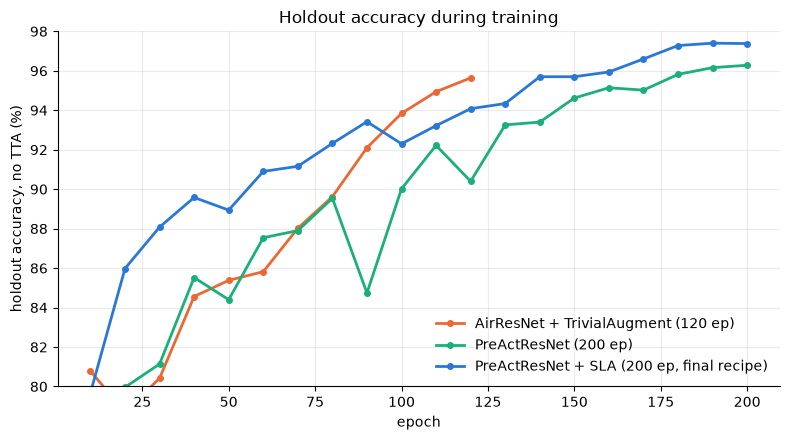

In [5]:
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
def hist(name):
    h = json.load(open(f'{ROOT}/results/runs/{name}/history.json'))
    return [e['epoch'] for e in h if 'val_acc' in e], [100 * e['val_acc'] for e in h if 'val_acc' in e]

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, label, color in [('w128-256-352_ta_e120', 'AirResNet + TrivialAugment (120 ep)', ORANGE),
                           ('preact_ta_e200', 'PreActResNet (200 ep)', AQUA),
                           ('preact_sla_ta_e200', 'PreActResNet + SLA (200 ep, final recipe)', BLUE)]:
    e, a = hist(name)
    ax.plot(e, a, color=color, lw=2, marker='o', ms=4, label=label)
ax.set_xlabel('epoch'); ax.set_ylabel('holdout accuracy, no TTA (%)')
ax.set_ylim(80, 98); ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower right'); ax.set_title('Holdout accuracy during training')
plt.tight_layout(); plt.show()

## 5. Results of all experiments

,run,arch,ssl,epochs,params,holdout_tta,minutes
0,w128-256-352_ta_e40,air,none,40,4846648,94.98,13.6
1,w96-192-384_d111_e40,air,none,40,4342008,95.10,9.1
2,w96-256-352_d211_e40,air,none,40,4803064,95.36,13.2
3,w128-256-352_d111_e40,air,none,40,4846648,95.58,13.6
4,ta_e120_b1024_a100,air,none,120,4846648,95.90,4.0
5,w128-256-352_e120,air,none,120,4846648,96.02,40.6
6,papa4_preact_ta_e200,preact,none,200,4696394,96.20,103.1
7,w128-256-352_ta_e120,air,none,120,4846648,96.20,40.9
8,ta_e120_b1024_s1,air,none,120,4846648,96.28,4.0
9,sla_ta_e120_b1024,air,sla,120,4860728,96.30,12.4


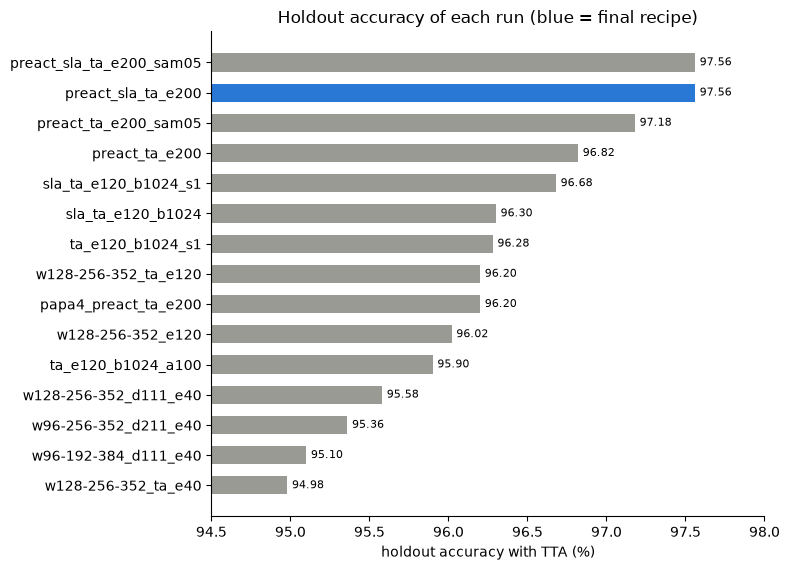

In [6]:
rows = []
for d in sorted(glob.glob(f'{ROOT}/results/runs/*')):
    c = json.load(open(d + '/config.json'))
    if not c.get('val'):
        continue
    rows.append(dict(run=os.path.basename(d), arch=c.get('arch', 'air'), ssl=c.get('ssl', 'none'),
                     epochs=int(c['epochs']), params=c['params_total'],
                     holdout_tta=round(100 * c['val_acc_tta'], 2), minutes=round(c['train_time'] / 60, 1)))
table = pd.DataFrame(rows).sort_values('holdout_tta')
display(table.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 0.32 * len(table) + 1))
colors = [BLUE if r == 'preact_sla_ta_e200' else '#9a9a95' for r in table.run]
ax.barh(table.run, table.holdout_tta, color=colors, height=0.6)
for y, v in enumerate(table.holdout_tta):
    ax.text(v + 0.03, y, f'{v:.2f}', va='center', fontsize=8)
ax.set_xlim(94.5, 98); ax.set_xlabel('holdout accuracy with TTA (%)')
ax.spines[['top', 'right']].set_visible(False); ax.set_title('Holdout accuracy of each run (blue = final recipe)')
plt.tight_layout(); plt.show()

## 6. Holdout accuracy and Kaggle public score

The dashed line is the CIFAR-10 → CIFAR-10.1 relation of Recht et al. (2018): new = 1.62 × old − 65.51.

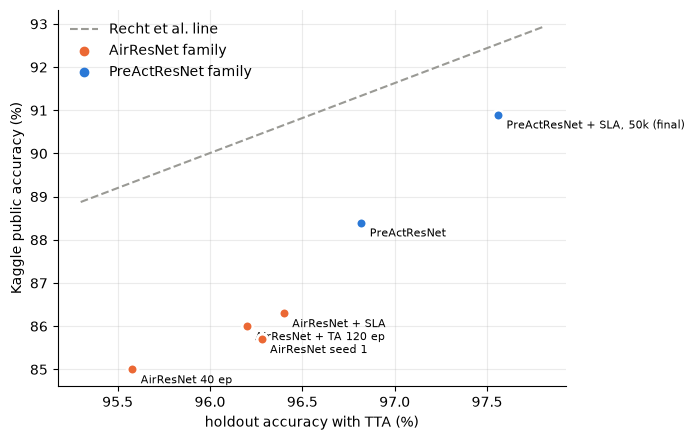

In [7]:
pts = [('AirResNet 40 ep', 95.58, 85.0, ORANGE, (8, -4)), ('AirResNet + TA 120 ep', 96.20, 86.0, ORANGE, (-120, 6)),
       ('AirResNet + SLA', 96.40, 86.3, ORANGE, (8, 4)), ('AirResNet seed 1', 96.28, 85.7, ORANGE, (8, -12)),
       ('PreActResNet', 96.82, 88.4, BLUE, (8, -4)), ('PreActResNet + SLA, 50k (final)', 97.56, 90.9, BLUE, (-170, 6))]
fig, ax = plt.subplots(figsize=(7, 4.5))
xs = np.linspace(95.3, 97.8, 10)
ax.plot(xs, 1.62 * xs - 65.51, ls='--', color='#9a9a95', lw=1.5, label='Recht et al. line')
for name, h, k, c, off in pts:
    ax.scatter(h, k, s=60, color=c, edgecolor='white', linewidth=2, zorder=3)
    ax.annotate(name, (h, k), textcoords='offset points', xytext=off, fontsize=8)
ax.scatter([], [], color=ORANGE, label='AirResNet family'); ax.scatter([], [], color=BLUE, label='PreActResNet family')
ax.set_xlabel('holdout accuracy with TTA (%)'); ax.set_ylabel('Kaggle public accuracy (%)')
ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

## 7. Final result

In [8]:
print('Final model                : PreActResNet (4/4/3 blocks, 64/128/256) + SLA+SD, trained on all 50,000 images')
print(f'Trainable parameters       : {n_all:,} (torchsummary forward pass: 4,696,394)')
print(f'Holdout accuracy (45k run) : {acc(both):.2f}%')
print('Kaggle public accuracy     : 0.909')

Final model                : PreActResNet (4/4/3 blocks, 64/128/256) + SLA+SD, trained on all 50,000 images
Trainable parameters       : 4,706,674 (torchsummary forward pass: 4,696,394)
Holdout accuracy (45k run) : 97.54%
Kaggle public accuracy     : 0.909
